# Visualize Cohort Statistics

- Creator: Arpit Merchant (am84@sanger.ac.uk).
- Date of Creation: 20.01.2025
- Date of Last Modification: 21.01.2025 (Sebastian Birk; sebastian.birk@helmholtz-munich.de)

- Run this notebook in the NicheJEPA environment, installable from ```envs/nichejepa.yml```
- Before running this notebook, run ```./collect_cohort_statistics.py```

## 1. Setup

### 1.1 Import Libraries

In [1]:
import os
import warnings
from pathlib import Path

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import ConnectionPatch
from scipy.stats import linregress, t

### 1.2 Run Notebook Setup

In [2]:
warnings.filterwarnings("ignore")

### 1.3 Configure Paths and Create Directories

In [3]:
# Define paths
st_data_folder_path = "/lustre/scratch126/cellgen/team361/DATASETS" # spatially resolved transcriptomics data
st_data_bronze_folder_path = f"{st_data_folder_path}/bronze"
st_data_silver_folder_path = f"{st_data_folder_path}/silver"
st_data_gold_folder_path = f"{st_data_folder_path}/gold"

artifacts_folder_path = '../../artifacts'
data_artifacts_folder_path = '../../artifacts/data'

# Create required directories
os.makedirs(st_data_bronze_folder_path, exist_ok=True)
os.makedirs(st_data_silver_folder_path, exist_ok=True)
os.makedirs(st_data_gold_folder_path, exist_ok=True)

os.makedirs(data_artifacts_folder_path, exist_ok=True)

## 2. Create Figures for ISTH-Corpus-60M

In [4]:
# Read corpus statistics
df = pd.read_csv(f'{data_artifacts_folder_path}/human_cohort1_60m_statistics.csv')
display(df.head())

num_datasets = df['dataset_id'].nunique()
print(f"Number of Datasets: {num_datasets}")

num_batches = len(df)
print(f"Number of Batches: {num_batches}")

num_cells = df['n_cells'].sum()
print(f"Number of Cells: {num_cells}")

,cohort_name,dataset_name,dataset_id,batch,n_cells,n_genes,min_counts_per_cell,max_counts_per_cell,median_counts_per_cell,min_genes_per_cell,max_genes_per_cell,median_genes_per_cell,assay,species,tissue,adata_batch_path
0,human_cohort1_60m,mhb14-1b_1p,14,batch0,689546,498,10.0,6004.0,342.0,10,366,123.0,merfish,homo_sapiens,breast,/lustre/scratch126/cellgen/team361/DATASETS/si...
1,human_cohort1_60m,mhc15-2b_1p,15,batch0,649711,498,10.0,5320.0,352.0,10,335,118.0,merfish,homo_sapiens,colon,/lustre/scratch126/cellgen/team361/DATASETS/si...
2,human_cohort1_60m,mhc15-2b_1p,15,batch1,779379,498,10.0,10207.0,329.0,10,401,113.0,merfish,homo_sapiens,colon,/lustre/scratch126/cellgen/team361/DATASETS/si...
3,human_cohort1_60m,mhl16-2b_1p,16,batch0,582921,498,10.0,3483.0,289.0,10,292,92.0,merfish,homo_sapiens,liver,/lustre/scratch126/cellgen/team361/DATASETS/si...
4,human_cohort1_60m,mhl16-2b_1p,16,batch1,531649,498,10.0,5241.0,259.0,10,330,93.0,merfish,homo_sapiens,liver,/lustre/scratch126/cellgen/team361/DATASETS/si...


Number of Datasets: 64
Number of Batches: 277
Number of Cells: 59605122


In [5]:
# Rename columns for plots
df.rename(
    columns={
        "median_counts_per_cell": "Median Counts Per Cell",
        "median_genes_per_cell": "Median Genes Per Cell",
        "n_cells": "Number of Cells",
        "n_genes": "Number of Genes"
    },
    inplace=True
)

In [6]:
# Rename assay for plots
ASSAY_NAME_MAP = {
    'xenium': 'Xenium',
    'merfish': 'MERFISH',
    'cosmx': 'CosMx',
    'cartana': 'CARTANA',
    'starmap': 'STARmap'
}

df['assay'] = df['assay'].apply(lambda x: ASSAY_NAME_MAP[x])

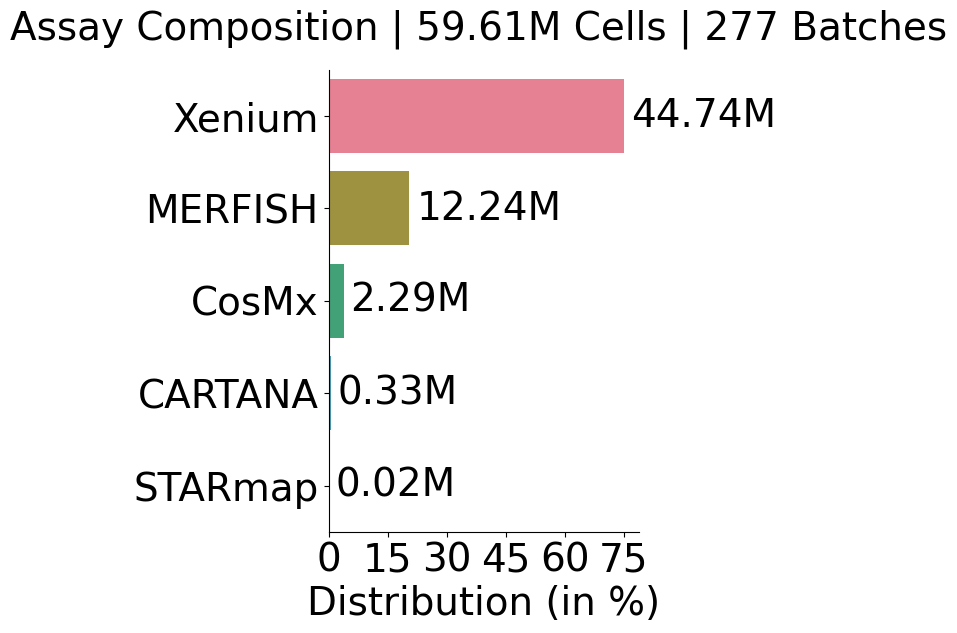

In [7]:
### Fig. 1b: Assay composition ###
def assay_distribution(
    num_cells,
    num_datasets,
    df,
    xname='percentage',
):
    # ----------------Process DataFrame----------------
    
    assay_counts = df.groupby("assay")['Number of Cells'].sum().reset_index()
    assay_counts['percentage'] = (assay_counts['Number of Cells'] / num_cells) * 100
    assay_counts = assay_counts.sort_values(by='Number of Cells', ascending=False)
    
    # ----------------Plot Settings----------------
    plt.rcParams.update({
        'font.size': 28,
        'font.family': 'sans-serif',
    })
    _, ax = plt.subplots(1, 1, figsize=(4, 6))
    colors = sns.color_palette('husl', len(assay_counts))
    
    # ----------------Draw Figure----------------
    
    sns.barplot(
        data=assay_counts,
        x=xname,
        y="assay",
        hue='assay',
        legend=False,
        palette=colors,
        ax=ax,
        )
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # ----------------Annotations----------------

    n_cells_assay = list(assay_counts['Number of Cells'])
    for i, container in enumerate(ax.containers):
        ax.bar_label(container, labels=[f'{(n_cells_assay[i]/1e6):.2f}M'], label_type='edge', padding=5)

    # ----------------Labels----------------
    
    if xname == 'percentage':
        xlabel = 'Distribution (in %)'
    elif xname == 'Number of Cells':
        xlabel = 'Number of Cells'
    ax.set_xlabel(f"{xlabel}")
    ax.xaxis.set_major_locator(ticker.MultipleLocator(15))
    #ax.grid(axis='x', which='major', linestyle='--', color='gray', alpha=0.5)
    ax.set_ylabel('')
    plt.suptitle(f"Assay Composition | {num_cells/1e6:.2f}M Cells | {num_batches} Batches", fontsize=28)
    plt.savefig(f"{data_artifacts_folder_path}/human_cohort1_60m_assay_composition.svg", dpi=300, bbox_inches='tight')

    # ----------------Visualize----------------
    plt.show()


assay_distribution(
    num_cells,
    num_datasets,
    df,
    xname='percentage',
    )

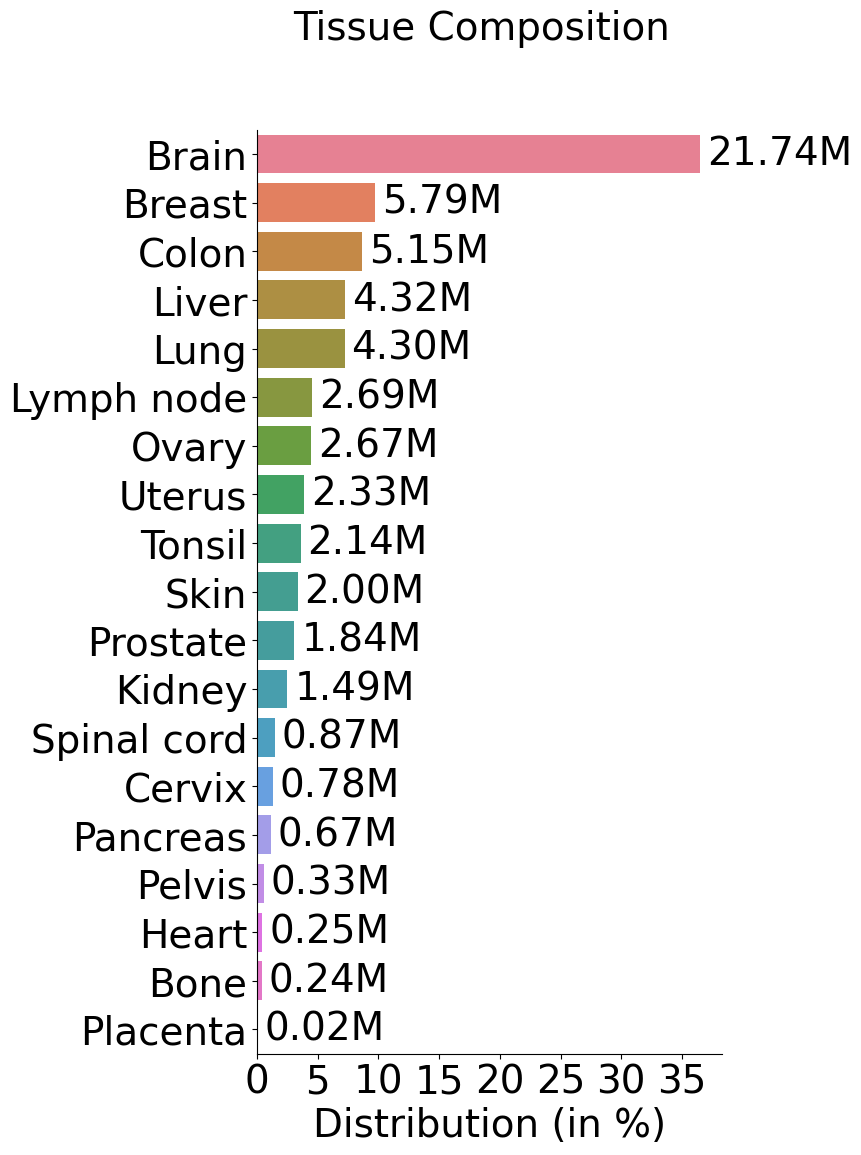

In [8]:
### Fig. 1b: Tissue composition ###
def tissue_distribution(
    num_cells,
    num_datasets,
    df,
    xname='percentage',
):
    # ----------------Process DataFrame----------------
    
    tissue_counts = df.groupby("tissue")['Number of Cells'].sum().reset_index()
    tissue_counts['percentage'] = (tissue_counts['Number of Cells'] / num_cells) * 100
    tissue_counts = tissue_counts.sort_values(by='Number of Cells', ascending=False)
    tissue_counts['tissue'] = tissue_counts['tissue'].str.capitalize()
    tissue_counts['tissue'] = tissue_counts['tissue'].replace('Spinal_cord', 'Spinal cord')
    tissue_counts['tissue'] = tissue_counts['tissue'].replace('Male_reproductive_system', 'Pelvis')

    # ----------------Plot Settings----------------
    plt.rcParams.update({
        'font.size': 28,
        'font.family': 'sans-serif',
    })
    _, ax = plt.subplots(1, 1, figsize=(6, 12))
    colors = sns.color_palette('husl', len(tissue_counts))
    
    # ----------------Draw Figure----------------
    
    sns.barplot(
        data=tissue_counts,
        x=xname,
        y="tissue",
        hue='tissue',
        legend=False,
        palette=colors,
        ax=ax,
        )
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # ----------------Annotations----------------

    n_cells_tissue = list(tissue_counts['Number of Cells'])
    for i, container in enumerate(ax.containers):
        ax.bar_label(container, labels=[f'{(n_cells_tissue[i]/1e6):.2f}M'], label_type='edge', padding=5)

    # ----------------Labels----------------
    
    if xname == 'percentage':
        xlabel = 'Distribution (in %)'
    elif xname == 'Number of Cells':
        xlabel = 'Number of Cells'
    ax.set_xlabel(f"{xlabel}")
    ax.xaxis.set_major_locator(ticker.MultipleLocator(5))
    ax.set_ylabel('')
    plt.suptitle(f"Tissue Composition", fontsize=28)
    plt.savefig(f"{data_artifacts_folder_path}/human_cohort1_60m_tissue_composition.svg", dpi=300, bbox_inches='tight')

    # ----------------Visualize----------------
    plt.show()


tissue_distribution(
    num_cells,
    num_datasets,
    df,
    xname='percentage',
    )

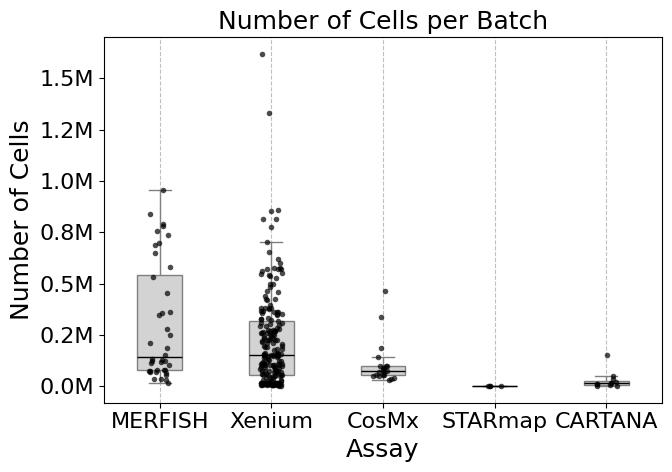

In [9]:
### Fig. 1: Number of Cells per Batch ###
def plot_box_with_dots(df):
    """
    Creates a boxplot with overlaid dots for the "Number of Cells" per "assay".
    - Box colors are set to grey.
    - Overlay dots are set to black.
    - Font sizes are increased for better readability.
    - Y-axis labels are formatted to show millions (e.g., "2.5M" instead of "2.5e6").
    - Title is set to "Number of Cells per Batch".
    """
    
    # 1) Increase the overall font size and set font family
    plt.rcParams.update({
        'font.size': 16,        # Global font size
        'font.family': 'sans-serif',
    })

    # 2) Create the plot
    fig, ax = plt.subplots(figsize=(7, 5))

    # 3) Boxplot with narrower boxes and grey colors
    sns.boxplot(
        data=df,
        x="assay",
        y="Number of Cells",
        showfliers=False,   # Hide outlier points to reduce clutter
        width=0.4,          # Narrower boxes
        ax=ax,
        boxprops={
            'facecolor': 'lightgrey',  # Light grey fill
            'edgecolor': 'grey'        # Grey edges
        },
        medianprops={
            'color': 'black'           # Black median line
        },
        whiskerprops={
            'color': 'grey'            # Grey whiskers
        },
        capprops={
            'color': 'grey'            # Grey caps
        }
    )

    # 4) Overlay the dots (black)
    sns.stripplot(
        data=df,
        x="assay",
        y="Number of Cells",
        color="black",      # Black dots
        alpha=0.7,          # Slight transparency
        size=4,             # Dot size
        jitter=True,        # Spread out points horizontally
        ax=ax
    )

    # 5) Format y-axis to show millions (e.g., "2.5M" instead of "2.5e6")
    ax.yaxis.set_major_formatter(
        ticker.FuncFormatter(lambda x, pos: f"{x/1e6:.1f}M")
    )

    # 6) Change axis labels
    ax.set_ylabel("Number of Cells", fontsize=18)
    ax.set_xlabel("Assay", fontsize=18)

    # 7) Add title
    ax.set_title("Number of Cells per Batch", fontsize=18)

    # 8) Add vertical gridlines for better readability
    ax.grid(
        axis='x',
        which='major',
        linestyle='--',  # Dash pattern: 5 points on, 10 points off
        color='grey',
        alpha=0.5
    )

    # 9) Adjust layout to prevent clipping of labels and title
    plt.tight_layout()

    # 10) Save the figure (optional)
    # plt.savefig("assay_distribution_boxplot.svg", dpi=300, bbox_inches='tight')

    # 11) Display the plot
    plt.savefig(f"{data_artifacts_folder_path}/human_cohort1_60m_cells_per_batch.svg", dpi=300, bbox_inches='tight')
    plt.show()

# Usage:
plot_box_with_dots(df)

0.04874235970987846
153.47685995534525


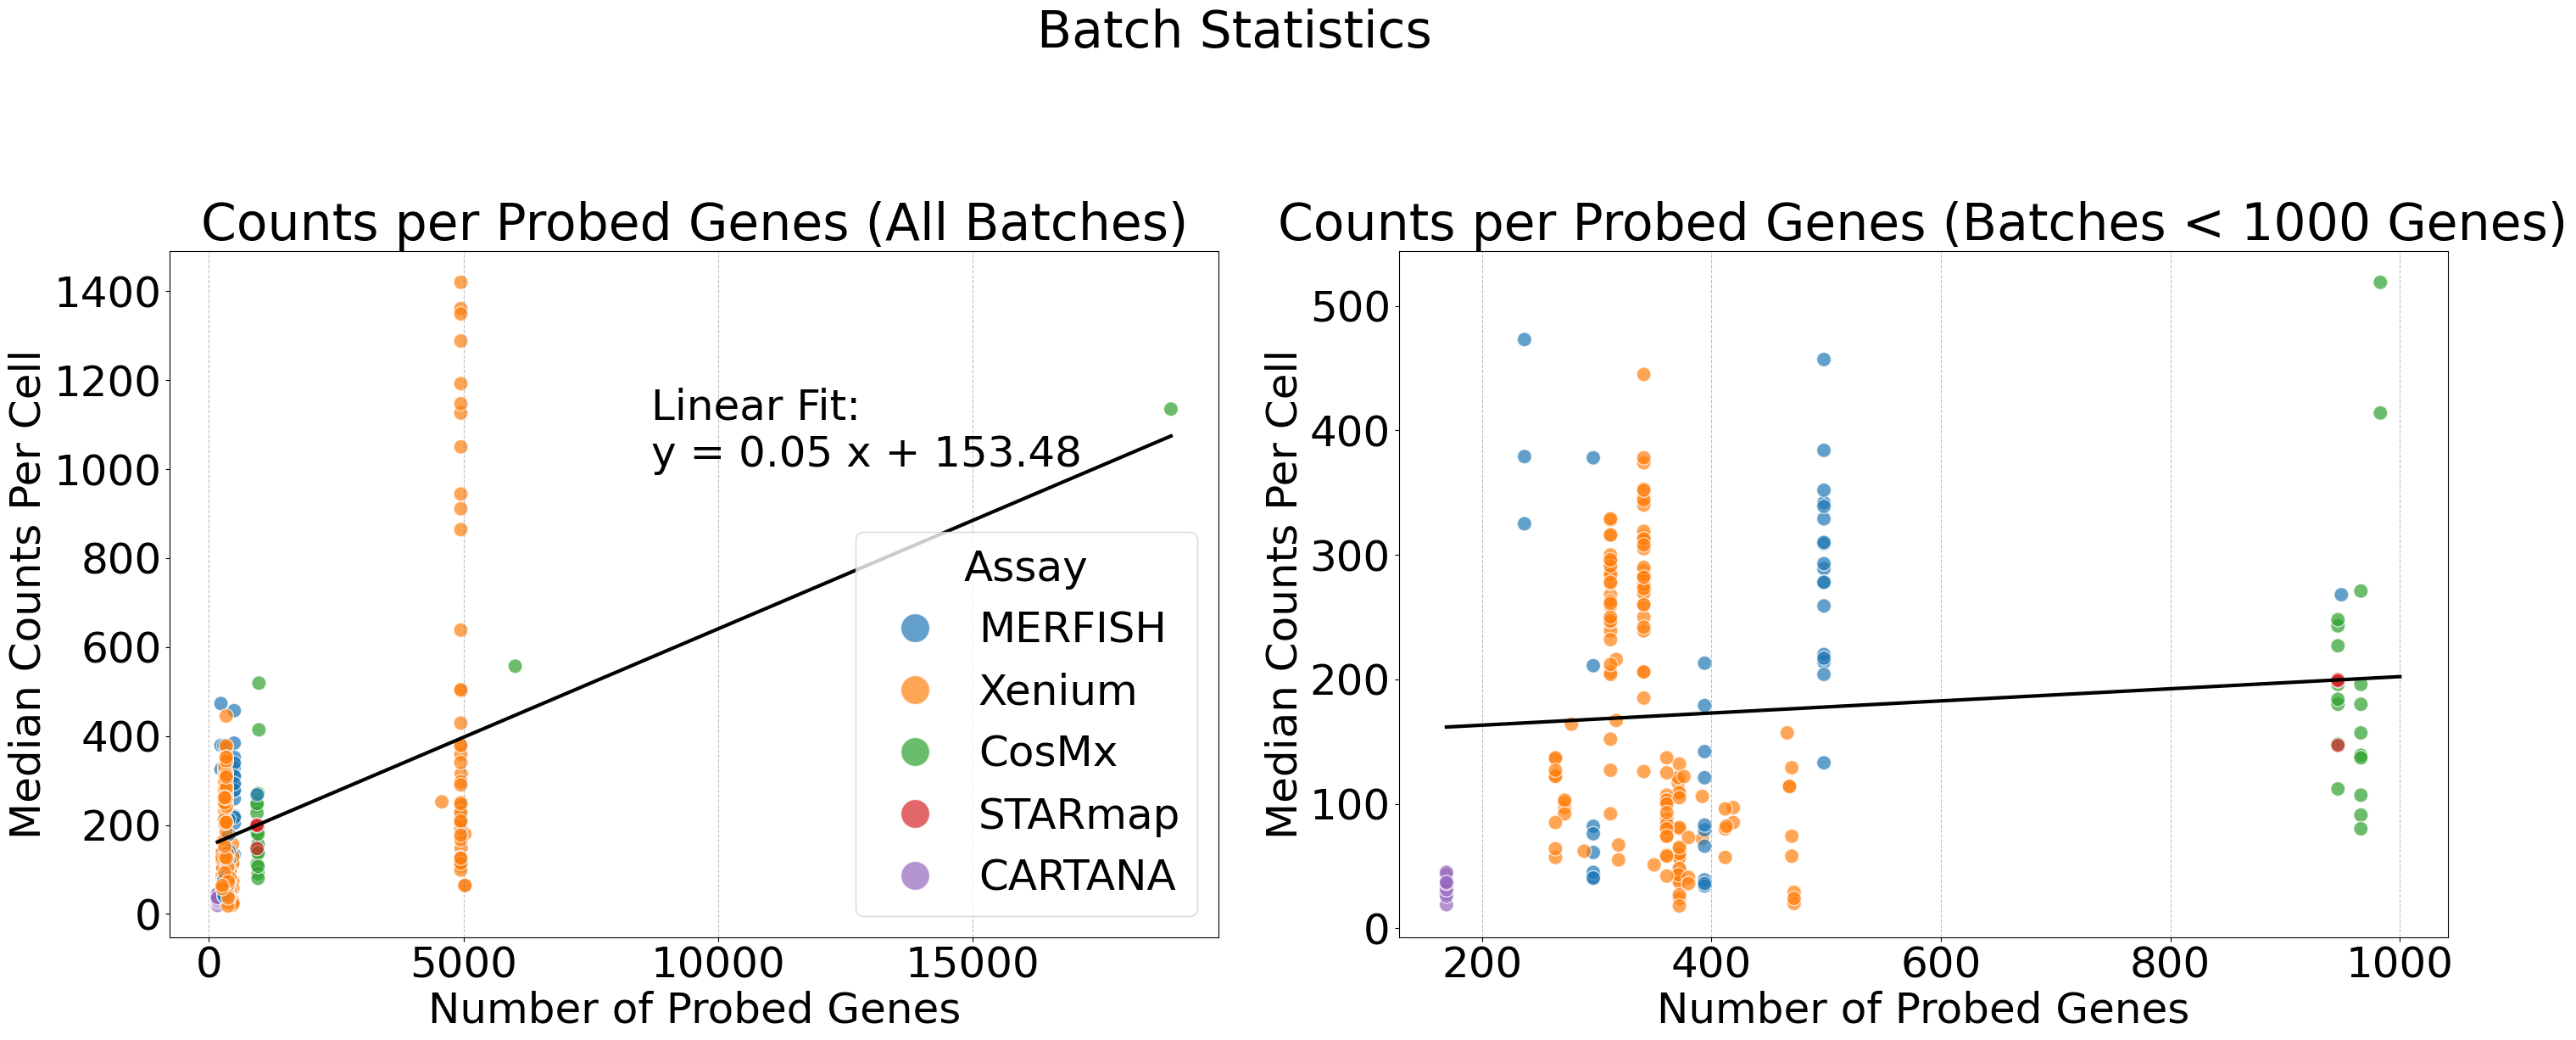

In [27]:
### Fig. 1: Counts per Probed Genes ### 
def jointplot_linear_regression_dual_zoomed(df):
    """
    Creates a figure with two subplots:
    - Left: Full dataset with per-assay and global linear regression lines.
    - Right: Subset (Number of Genes < 1000) with per-assay regression lines
             and the global regression line from the full dataset (clipped to x < 1000).
             
    Each subplot has its own y-axis, providing a true zoom-in effect for the subset.
    Font sizes are increased for better readability, and the "Global Fit" label is removed from the legends.
    
    Parameters:
    - df (pd.DataFrame): DataFrame containing the data with columns "assay", "Number of Genes", and "Median Counts Per Cell".
    """
    
    # 1. Increase global font size & set font family
    plt.rcParams.update({
        'font.size': 36,            # Increased global font size
        'font.family': 'sans-serif',
    })
    
    point_size = 150  # Larger scatter markers for better visibility
    
    # 2. Create a figure with two subplots side by side
    fig, axes = plt.subplots(1, 2, figsize=(30, 12), sharey=False)
    
    # Define colors for assays
    unique_assays = df["assay"].unique()
    colors = sns.color_palette(n_colors=len(unique_assays))
    assay_color_map = {assay: colors[i] for i, assay in enumerate(unique_assays)}
    
    # -------------- Helper Function --------------
    def fit_linear_regression(x, y):
        """
        Fits a linear regression: y = intercept + slope * x
        Returns slope, intercept, and r_value.
        """
        valid_mask = ~np.isnan(x) & ~np.isnan(y)
        x_valid = x[valid_mask]
        y_valid = y[valid_mask]
        
        if len(x_valid) < 2:
            return None, None, None  # Not enough data to fit
        
        slope, intercept, r_val, p_val, std_err = linregress(x_valid, y_valid)
        
        return slope, intercept, r_val
    
    # -------------- Plot 1: Full Dataset --------------
    ax1 = axes[0]
    
    # Scatter plot
    sns.scatterplot(
        data=df,
        x="Number of Genes",
        y="Median Counts Per Cell",
        hue="assay",
        palette=assay_color_map,
        s=point_size,
        alpha=0.7,
        edgecolor='white',
        ax=ax1
    )
    
    # Fit and plot global regression line (without label)
    slope_g, intercept_g, r_val_g = fit_linear_regression(df["Number of Genes"].values, df["Median Counts Per Cell"].values)
    if slope_g is not None:
        x_vals_global = np.linspace(df["Number of Genes"].min(), df["Number of Genes"].max(), 200)
        y_vals_global = intercept_g + slope_g * x_vals_global
        ax1.plot(x_vals_global, y_vals_global, color='black', lw=3, label=None)  # label=None removes it from legend
        
        # Annotate global fit
        idx_annot = int(0.9 * len(x_vals_global))
        x_text = x_vals_global[idx_annot]
        y_text = y_vals_global[idx_annot]
        x_range = df["Number of Genes"].max() - df["Number of Genes"].min()
        x_text -= 0.45 * x_range
        print(slope_g)
        print(intercept_g)
        eq_text = f"Linear Fit:\ny = {slope_g:.2f} x + {intercept_g:.2f}"
        ax1.text(
            x_text,
            y_text,
            eq_text,
            color="black",
            ha="left",
            va="bottom"
        )
    
    # Legend (only assays, no 'Global Fit')
    handles, labels = ax1.get_legend_handles_labels()
    # Remove 'Global Fit' if it was accidentally included
    handles_labels = dict(zip(labels, handles))
    if 'Global Fit' in handles_labels:
        del handles_labels['Global Fit']
    ax1.legend(
        handles=handles_labels.values(),
        labels=handles_labels.keys(),
        title="Assay",
        loc='lower right',
        markerscale=2,
        handletextpad=0.5
    )
    
    # Title
    ax1.set_title("Counts per Probed Genes (All Batches)")
    
    # -------------- Plot 2: Subset Data (Number of Genes < 1000) --------------
    ax2 = axes[1]
    
    # Subset data
    subset_df = df[df["Number of Genes"] < 1000]
    
    # Scatter plot without legend
    sns.scatterplot(
        data=subset_df,
        x="Number of Genes",
        y="Median Counts Per Cell",
        hue="assay",
        palette=assay_color_map,
        s=point_size,
        alpha=0.7,
        edgecolor='white',
        ax=ax2,
        legend=False  # Disable legend for the second subplot
    )
    
    # Fit and plot global regression line (clipped to x < 1000)
    if slope_g is not None:
        x_vals_global_subset = np.linspace(df["Number of Genes"].min(), 1000, 200)
        y_vals_global_subset = intercept_g + slope_g * x_vals_global_subset
        ax2.plot(x_vals_global_subset, y_vals_global_subset, color='black', lw=3, label=None)  # label=None removes it from legend
    
    # Remove legend from the second subplot entirely
    # (Already disabled via `legend=False`, but ensuring no legend exists)
    if ax2.get_legend() is not None:
        ax2.get_legend().remove()
    
    # Title
    ax2.set_title("Counts per Probed Genes (Batches < 1000 Genes)")
    
    # -------------- Common Settings --------------
    
    # Format y-axis to show raw counts (no scaling)
    for ax in axes:
        ax.yaxis.set_major_formatter(
            ticker.FuncFormatter(lambda x, pos: f"{int(x)}")
        )
        ax.set_xlabel("Number of Probed Genes")
        ax.set_ylabel("Median Counts Per Cell")
    
    # Overall Figure Title
    fig.suptitle("Batch Statistics", y=1.05)
    
    # Adjust layout to prevent overlapping
    plt.tight_layout(rect=[0, 0, 1, 1])
    
    # -------------- Add Gridlines (Optional) --------------
    for ax in axes:
        ax.grid(
            axis='x',
            which='major',
            linestyle='--',  # Dash pattern: 5 points on, 10 points off
            color='grey',
            alpha=0.5
        )
    
    # -------------- Save and Show --------------
    # Uncomment the following line to save the figure
    plt.savefig(f"{data_artifacts_folder_path}/human_cohort1_60m_counts_per_probed_genes.svg", dpi=300, bbox_inches='tight')
    
    plt.show()

# **Usage:**
jointplot_linear_regression_dual_zoomed(df)

In [18]:
min(df['Number of Genes'])

169

In [19]:
x = (-456.68 + 61.35 * np.log2(1))
print(x)

-456.68


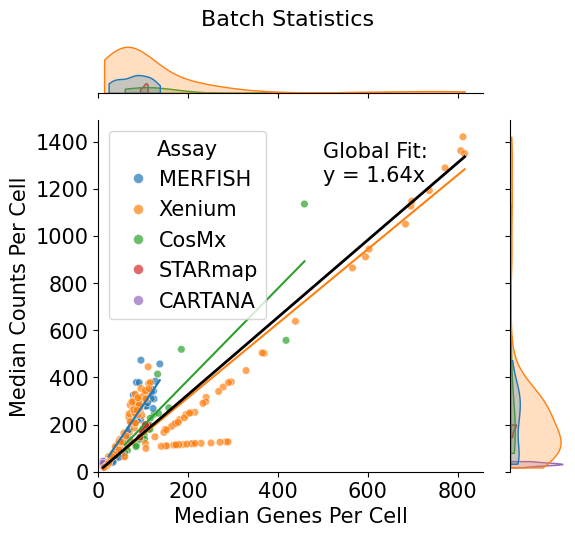

In [20]:
def forced_regression_through_origin(x, y):
    """
    Perform a linear regression forced through the origin (y = slope * x).
    Returns (slope, r_value, std_err).
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    
    slope = np.sum(x * y) / np.sum(x * x)
    y_pred = slope * x

    ss_res = np.sum((y - y_pred)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    if ss_tot == 0:
        r_value = 0.0
    else:
        r_value = np.sqrt(1 - ss_res / ss_tot)

    n = len(x)
    var_slope = ss_res / ((n - 1) * np.sum(x * x))
    std_err = np.sqrt(var_slope)

    return slope, r_value, std_err

def jointplot_with_forced_origin_no_r2_swapped_no_line_legend(df):
    """
    - X axis: median_genes_per_cell
    - Y axis: median_counts_per_cell
    - Forced-origin lines per assay (excluded from legend)
    - Global forced-origin line in black, with equation near the line
    - Legend only from the scatter plot (assay colors)
    - Increased font size for all text, and a main title "Batch Statistics"
    """

    # 1) Increase the global font size via rcParams
    plt.rcParams.update({
        'font.size': 15,
        'font.family': 'sans-serif',
    })

    point_size = 30  # Larger scatter markers
    
    g = sns.jointplot(
        data=df,
        x="Median Genes Per Cell",
        y="Median Counts Per Cell",
        kind="scatter",
        hue="assay",
        joint_kws={'s': point_size, 'alpha': 0.7},  # larger markers
        marginal_kws={"cut": 0}
    )

    # 2) Force axes to start at 0
    g.ax_joint.set_xlim(left=0)
    g.ax_joint.set_ylim(bottom=0)

    # 3) Plot forced-origin lines per assay (no legend labels)
    unique_assays = df["assay"].unique()
    for assay_name in unique_assays:
        subset = df[df["assay"] == assay_name]
        
        slope, _, _ = forced_regression_through_origin(
            subset["Median Genes Per Cell"],
            subset["Median Counts Per Cell"]
        )
        
        x_vals = np.linspace(subset["Median Genes Per Cell"].min(),
                             subset["Median Genes Per Cell"].max(), 100)
        y_vals = slope * x_vals
        g.ax_joint.plot(x_vals, y_vals, label=None)

    # 4) Global forced-origin line (black)
    x_all = df["Median Genes Per Cell"].values
    y_all = df["Median Counts Per Cell"].values
    slope_g, _, _ = forced_regression_through_origin(x_all, y_all)
    
    x_vals_global = np.linspace(x_all.min(), x_all.max(), 100)
    y_vals_global = slope_g * x_vals_global
    g.ax_joint.plot(x_vals_global, y_vals_global, color="black", lw=2, label=None)

    # 5) Place equation near the line in data coordinates
    idx_70pct = int(0.9 * len(x_vals_global))
    x_text = x_vals_global[idx_70pct]
    y_text = y_vals_global[idx_70pct]

    x_range = x_all.max() - x_all.min()
    x_text -= 0.3 * x_range  # shift text to the left

    eq_text = f"Global Fit:\ny = {slope_g:.2f}x"
    g.ax_joint.text(
        x_text, 
        y_text,
        eq_text,
        color="black",
        ha="left",
        va="bottom"
    )

    # 6) Legend: only scatter (assay categories), bigger markers in legend
    g.ax_joint.legend(title="Assay", loc="upper left", markerscale=1.3, handletextpad=0.)

    # 7) Add a main (figure) title
    #    We use suptitle on g.fig to place a title above the entire plot.
    g.fig.suptitle("Batch Statistics", fontsize=16, y=0.9)

    # Adjust layout so title doesn’t overlap
    g.fig.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig(f"{data_artifacts_folder_path}/human_cohort1_60m_batchstatistics.svg", dpi=300, bbox_inches='tight')

    plt.show()

# Usage:
jointplot_with_forced_origin_no_r2_swapped_no_line_legend(df)

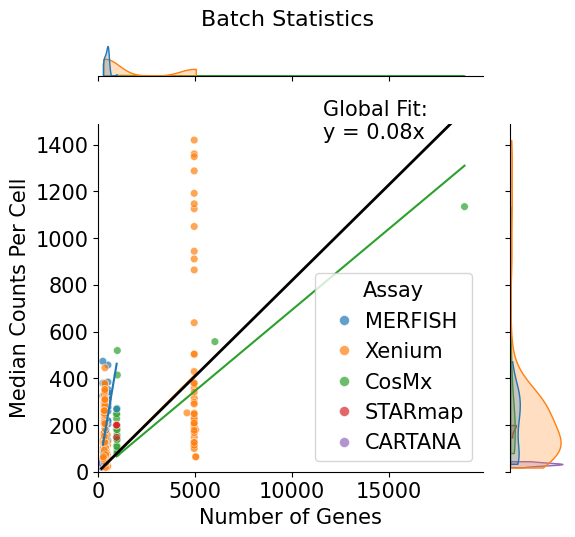

In [21]:
def forced_regression_through_origin(x, y):
    """
    Perform a linear regression forced through the origin (y = slope * x).
    Returns (slope, r_value, std_err).
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    
    slope = np.sum(x * y) / np.sum(x * x)
    y_pred = slope * x

    ss_res = np.sum((y - y_pred)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    if ss_tot == 0:
        r_value = 0.0
    else:
        r_value = np.sqrt(1 - ss_res / ss_tot)

    n = len(x)
    var_slope = ss_res / ((n - 1) * np.sum(x * x))
    std_err = np.sqrt(var_slope)

    return slope, r_value, std_err

def jointplot_with_forced_origin_no_r2_swapped_no_line_legend(df):
    """
    - X axis: median_genes_per_cell
    - Y axis: median_counts_per_cell
    - Forced-origin lines per assay (excluded from legend)
    - Global forced-origin line in black, with equation near the line
    - Legend only from the scatter plot (assay colors)
    - Increased font size for all text, and a main title "Batch Statistics"
    """

    # 1) Increase the global font size via rcParams
    plt.rcParams.update({
        'font.size': 15,
        'font.family': 'sans-serif',
    })

    point_size = 30  # Larger scatter markers
    
    g = sns.jointplot(
        data=df,
        x="Number of Genes",
        y="Median Counts Per Cell",
        kind="scatter",
        hue="assay",
        joint_kws={'s': point_size, 'alpha': 0.7},  # larger markers
        marginal_kws={"cut": 0}
    )

    # 2) Force axes to start at 0
    g.ax_joint.set_xlim(left=0)
    g.ax_joint.set_ylim(bottom=0)

    # 3) Plot forced-origin lines per assay (no legend labels)
    unique_assays = df["assay"].unique()
    for assay_name in unique_assays:
        subset = df[df["assay"] == assay_name]
        
        slope, _, _ = forced_regression_through_origin(
            subset["Number of Genes"],
            subset["Median Counts Per Cell"]
        )
        
        x_vals = np.linspace(subset["Number of Genes"].min(),
                             subset["Number of Genes"].max(), 100)
        y_vals = slope * x_vals
        g.ax_joint.plot(x_vals, y_vals, label=None)

    # 4) Global forced-origin line (black)
    x_all = df["Number of Genes"].values
    y_all = df["Median Counts Per Cell"].values
    slope_g, _, _ = forced_regression_through_origin(x_all, y_all)
    
    x_vals_global = np.linspace(x_all.min(), x_all.max(), 100)
    y_vals_global = slope_g * x_vals_global
    g.ax_joint.plot(x_vals_global, y_vals_global, color="black", lw=2, label=None)

    # 5) Place equation near the line in data coordinates
    idx_70pct = int(0.9 * len(x_vals_global))
    x_text = x_vals_global[idx_70pct]
    y_text = y_vals_global[idx_70pct]

    x_range = x_all.max() - x_all.min()
    x_text -= 0.3 * x_range  # shift text to the left

    eq_text = f"Global Fit:\ny = {slope_g:.2f}x"
    g.ax_joint.text(
        x_text, 
        y_text,
        eq_text,
        color="black",
        ha="left",
        va="bottom"
    )

    # 6) Legend: only scatter (assay categories), bigger markers in legend
    g.ax_joint.legend(title="Assay", loc="lower right", markerscale=1.3, handletextpad=0.)

    # 7) Add a main (figure) title
    #    We use suptitle on g.fig to place a title above the entire plot.
    g.fig.suptitle("Batch Statistics", fontsize=16, y=0.9)

    # Adjust layout so title doesn’t overlap
    g.fig.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig(f"{data_artifacts_folder_path}/human_cohort1_60m_batchstatistics3.svg", dpi=300, bbox_inches='tight')

    plt.show()

# Usage:
jointplot_with_forced_origin_no_r2_swapped_no_line_legend(df)

In [22]:
def forced_regression_through_origin_logY(x, y):
    """
    Forced regression in log-domain:
      ln(y) = slope * x, no intercept
    => y = exp(slope * x)
    
    Returns:
      slope (in log-domain),
      r_value (coefficient of determination in log-domain),
      a function pred_y(x) to get y-hat in original space.
    """
    # Ensure we use numpy arrays
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    # Filter out non-positive y, since log(y) undefined for y <= 0
    valid_mask = (y > 0) & ~np.isnan(y)
    x_valid = x[valid_mask]
    y_valid = y[valid_mask]

    # Transform y -> logY
    logy = np.log(y_valid)

    # Forced regression in log-space => slope = sum(x * logy) / sum(x^2)
    slope = np.sum(x_valid * logy) / np.sum(x_valid * x_valid)

    # Predicted logY
    logy_pred = slope * x_valid

    # Residuals in log-space
    res_log = logy - logy_pred

    ss_res = np.sum(res_log**2)
    ss_tot = np.sum((logy - np.mean(logy))**2)

    if ss_tot == 0:
        r_value = 0.0
    else:
        r_value = np.sqrt(1 - ss_res / ss_tot)

    # We can define a small function to compute predicted y in linear space
    def pred_y(x_input):
        # pred logY = slope * x_input
        return np.exp(slope * x_input)

    return slope, r_value, pred_y

In [ ]:
def forced_regression_through_origin(x, y):
    """
    Perform a linear regression forced through the origin (y = slope * x).
    Returns (slope, r_value, std_err).
    """
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    
    slope = np.sum(x * y) / np.sum(x * x)
    y_pred = slope * x

    ss_res = np.sum((y - y_pred)**2)
    ss_tot = np.sum((y - np.mean(y))**2)
    if ss_tot == 0:
        r_value = 0.0
    else:
        r_value = np.sqrt(1 - ss_res / ss_tot)

    n = len(x)
    var_slope = ss_res / ((n - 1) * np.sum(x * x))
    std_err = np.sqrt(var_slope)

    return slope, r_value, std_err

def jointplot_with_forced_origin_no_r2_swapped_no_line_legend(df):
    """
    - X axis: median_genes_per_cell
    - Y axis: median_counts_per_cell
    - Forced-origin lines per assay (excluded from legend)
    - Global forced-origin line in black, with equation near the line
    - Legend only from the scatter plot (assay colors)
    - Increased font size for all text, and a main title "Batch Statistics"
    """

    # 1) Increase the global font size via rcParams
    plt.rcParams.update({
        'font.size': 15,
        'font.family': 'sans-serif',
    })

    point_size = 30  # Larger scatter markers
    
    g = sns.jointplot(
        data=df,
        x="Number of Genes",
        y="Median Genes Per Cell",
        kind="scatter",
        hue="assay",
        joint_kws={'s': point_size, 'alpha': 0.7},  # larger markers
        marginal_kws={"cut": 0}
    )

    # 2) Force axes to start at 0
    g.ax_joint.set_xlim(left=0)
    g.ax_joint.set_ylim(bottom=0)

    # 3) Plot forced-origin lines per assay (no legend labels)
    unique_assays = df["assay"].unique()
    for assay_name in unique_assays:
        subset = df[df["assay"] == assay_name]
        
        slope, _, _ = forced_regression_through_origin(
            subset["Number of Genes"],
            subset["Median Genes Per Cell"]
        )
        
        x_vals = np.linspace(subset["Number of Genes"].min(),
                             subset["Number of Genes"].max(), 100)
        y_vals = slope * x_vals
        g.ax_joint.plot(x_vals, y_vals, label=None)

    # 4) Global forced-origin line (black)
    x_all = df["Number of Genes"].values
    y_all = df["Median Genes Per Cell"].values
    slope_g, _, _ = forced_regression_through_origin(x_all, y_all)
    
    x_vals_global = np.linspace(x_all.min(), x_all.max(), 100)
    y_vals_global = slope_g * x_vals_global
    g.ax_joint.plot(x_vals_global, y_vals_global, color="black", lw=2, label=None)

    # 5) Place equation near the line in data coordinates
    idx_70pct = int(0.9 * len(x_vals_global))
    x_text = x_vals_global[idx_70pct]
    y_text = y_vals_global[idx_70pct]

    x_range = x_all.max() - x_all.min()
    x_text -= 0.3 * x_range  # shift text to the left

    eq_text = f"Global Fit:\ny = {slope_g:.2f}x"
    g.ax_joint.text(
        x_text, 
        y_text,
        eq_text,
        color="black",
        ha="left",
        va="bottom"
    )

    # 6) Legend: only scatter (assay categories), bigger markers in legend
    g.ax_joint.legend(title="Assay", loc="lower right", markerscale=1.3, handletextpad=0.)

    # 7) Add a main (figure) title
    #    We use suptitle on g.fig to place a title above the entire plot.
    g.fig.suptitle("Batch Statistics", fontsize=16, y=0.9)

    # Adjust layout so title doesn’t overlap
    g.fig.tight_layout(rect=[0, 0, 1, 0.95])
    plt.savefig(f"{data_artifacts_folder_path}/human_cohort1_60m_batchstatistics4.svg", dpi=300, bbox_inches='tight')

    plt.show()

# Usage:
jointplot_with_forced_origin_no_r2_swapped_no_line_legend(df)

In [ ]:
def jointplot_with_ols_regression(df):
    """
    - X axis: Number of Genes
    - Y axis: Median Genes Per Cell
    - Ordinary linear regression lines per assay (excluded from legend)
    - One global OLS line in black, with equation near the line
    - Legend only for the scatter plot (assay colors)
    - Increased font size, main title "Batch Statistics"
    """

    # 1) Increase font size & set a font family
    plt.rcParams.update({
        'font.size': 15,
        'font.family': 'sans-serif',
    })

    point_size = 30  # larger scatter markers

    g = sns.jointplot(
        data=df,
        x="Number of Genes",
        y="Median Genes Per Cell",
        kind="scatter",
        hue="assay",
        joint_kws={'s': point_size, 'alpha': 0.7},
        marginal_kws={"cut": 0}
    )

    # 2) Force axes to start at 0 if you want
    g.ax_joint.set_xlim(left=0)
    g.ax_joint.set_ylim(bottom=0)

    # 3) OLS lines per assay (no legend labels)
    unique_assays = df["assay"].unique()
    for assay_name in unique_assays:
        print(assay_name)
        if (assay_name != "STARmap") and (assay_name != "CARTANA"):
            subset = df[df["assay"] == assay_name]
    
            # Perform ordinary linear regression
            slope, intercept, r_value, p_value, std_err = linregress(
                subset["Number of Genes"],
                subset["Median Genes Per Cell"]
            )
    
            # Create x-values for the line
            x_vals = np.linspace(subset["Number of Genes"].min(),
                                 subset["Number of Genes"].max(), 100)
            # y = slope*x + intercept
            y_vals = slope * x_vals + intercept
    
            g.ax_joint.plot(x_vals, y_vals, label=None)

    # 4) Global OLS line (in black)
    x_all = df["Number of Genes"].values
    y_all = df["Median Genes Per Cell"].values

    slope_g, intercept_g, r_value_g, p_value_g, std_err_g = linregress(x_all, y_all)

    x_vals_global = np.linspace(x_all.min(), x_all.max(), 100)
    y_vals_global = slope_g * x_vals_global + intercept_g
    g.ax_joint.plot(x_vals_global, y_vals_global, color="black", lw=2, label=None)

    # 5) Place equation near the black line in data coordinates
    idx_90pct = int(0.9 * len(x_vals_global))
    x_text = x_vals_global[idx_90pct]
    y_text = y_vals_global[idx_90pct]

    x_range = x_all.max() - x_all.min()
    x_text -= 0.3 * x_range  # shift text left so it doesn't overlap the line

    eq_text = f"Global Fit:\ny = {slope_g:.2f}x + {intercept_g:.2f}"
    g.ax_joint.text(
        x_text,
        y_text,
        eq_text,
        color="black",
        ha="left",
        va="bottom"
    )

    # 6) Legend for the scatter only
    g.ax_joint.legend(
        title="Assay",
        loc="lower right",
        markerscale=1.3,
        handletextpad=0.
    )

    # 7) Main title
    g.fig.suptitle("Batch Statistics", fontsize=16, y=0.9)
    g.fig.tight_layout(rect=[0, 0, 1, 0.95])

    # Save and show
    #plt.savefig(
    #    f"{data_artifacts_folder_path}/human_cohort1_60m_batchstatistics_ols.svg",
    #    dpi=300,
    #    bbox_inches='tight'
    #)
    plt.show()


# Usage:
jointplot_with_ols_regression(df)

In [ ]:
(300 * 0.04 + 54.36) / 300

In [ ]:
np.mean(df['Median Genes Per Cell'] / df['Number of Genes'])

In [ ]:
np.median(df['Median Genes Per Cell'] / df['Number of Genes'])

### Datasets with Tokenization Errors

### Statistics of GBM Data from Omer

In [ ]:
gbm_df = df[df['dataset_name'] == 'xhb1002-76b_3p']

In [ ]:
def get_donor_id(filename):
    filename = Path(filename).name
    return filename.split('-')[0].split('_')[0]

gbm_df['donor_id'] = gbm_df['adata_batch_path'].apply(get_donor_id)
gbm_donor_summary = gbm_df.groupby('donor_id')['n_cells'].sum().reset_index()
gbm_donor_summary = gbm_donor_summary.sort_values(by='n_cells', ascending=False)
display(gbm_donor_summary)

### Full Corpus Distribution

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_density(df):
    # Create a figure with 2 subplots
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Density plot for n_cells
    sns.kdeplot(
        data=df,
        x="n_cells",
        fill=True,        # Fill under the curve
        common_norm=False, # If you don't want all densities to sum to 1
        ax=axes[0]
    )
    axes[0].set_title("Density of n_cells")
    axes[0].set_xlabel("Number of Cells")
    axes[0].set_ylabel("Density")

    # Density plot for n_genes
    sns.kdeplot(
        data=df,
        x="n_genes",
        fill=True,
        common_norm=False,
        ax=axes[1]
    )
    axes[1].set_title("Density of n_genes")
    axes[1].set_xlabel("Number of Genes")
    axes[1].set_ylabel("Density")

    # Adjust layout
    plt.tight_layout()
    plt.show()

# Usage:
plot_density(df)

In [ ]:
import matplotlib.ticker as ticker

def jointplot(df):
    # Increase the global font size and set font family
    plt.rcParams.update({
        'font.size': 16,
        'font.family': 'sans-serif',
    })

    point_size = 30  # Larger scatter markers
    
    g = sns.jointplot(
        data=df,
        x="Number of Genes",
        y="Number of Cells",
        kind="scatter",
        hue="assay",
        joint_kws={'s': point_size, 'alpha': 0.7},  # larger markers
        marginal_kws={"cut": 0}
    )

    # Force axes to start at 0 (optional)
    g.ax_joint.set_xlim(left=0)
    g.ax_joint.set_ylim(bottom=0)

    # --- Formatter for millions ---
    def millions_formatter(x, pos):
        return f"{x/1e6:.2f}M"

    # Apply the formatter on the X axis and Y axis
    g.ax_joint.yaxis.set_major_formatter(ticker.FuncFormatter(millions_formatter))

    # Optionally rename the axes labels to reflect the new units (Millions)
    g.ax_joint.set_xlabel("Number of Genes")
    g.ax_joint.set_ylabel("Number of Cells (M)")

    # Legend: only scatter (assay categories), bigger markers in legend
    g.ax_joint.legend(
        title="Assay", 
        loc="upper right", 
        markerscale=1.3, 
        handletextpad=0.
    )

    # Save figure
    plt.savefig(f"{data_artifacts_folder_path}/human_cohort1_60m_batchstatistics2.svg", dpi=300, bbox_inches='tight')
    plt.show()

# Usage:
jointplot(df)